# Exploring the ARC-AGI SDK

ARC-AGI is a benchmark of small grid games. Each game is a tiny world with its own
rules: the player has to figure out what the symbols mean and which actions lead to
a win.

This notebook is a hands-on tour of the public **ARC SDK** (`arc_agi`):

1. **Load** a game from disk.
2. Look at how the environment represents the game **internally**.
3. **Render** the board so we can see it.
4. **Step** through actions and watch what changes.
5. Let an **LLM** choose the moves for us.

Everything here is plain Python, the ARC SDK, and an OpenAI-compatible chat API.


## 0. Install what we need

`arc-agi` ships the SDK, `arcengine` is its runtime, and `pillow` + `matplotlib`
draw the board. `openai` is only used for the LLM part at the end.


In [1]:
%pip install -q "arc-agi==0.9.9" pillow matplotlib openai

Note: you may need to restart the kernel to use updated packages.


## 1. Loading a game

The SDK entry point is `arc_agi.Arcade`. It can run in different **operation modes**:

| mode | what it does |
|---|---|
| `NORMAL` / `ONLINE` | can talk to the ARC servers (e.g. to fetch a public game) |
| `OFFLINE` | loads everything from the local `environment_files/` folder |

We open the arcade in `NORMAL` mode. The first `make(...)` call downloads the game
into `environment_files/`, so you can switch to `OFFLINE` afterwards if you want to
work without the network.


In [2]:
from pathlib import Path

import arc_agi
from arc_agi import OperationMode

GAME_ID = "ls20"
ENVIRONMENTS_DIR = "./environment_files"

arcade = arc_agi.Arcade(
    operation_mode=OperationMode.NORMAL,   # NORMAL can download; OFFLINE needs a prior download
    environments_dir=ENVIRONMENTS_DIR,
)

print(f"{GAME_ID} is available in {ENVIRONMENTS_DIR}")


INFO:arc_agi.scorecard:Initialized ScorecardManager with idle_for=0:15:00 and max_open_for=3 days, 0:00:00
2026-10-14 09:21:43 | INFO | Got anonymous API key: 5eb9f6e0-9996-4c4f-aa17-79f76e3c02ef
2026-10-14 09:21:43 | INFO | You can register for an API key at https://three.arcprize.org
2026-10-14 09:21:44 | INFO | Successfully fetched 25 environment(s) from API
ls20 is available in ./environment_files


## 2. The environment object

`arcade.make(GAME_ID)` returns an **environment**. Before playing, we can ask it what
it expects and what it offers:

* `action_space` — the actions the game accepts,
* `observation_space` — the shape of every observation,
* `info` — metadata about the game.


In [3]:
env = arcade.make(GAME_ID)

print("Environment:", type(env).__name__)
print("Action space:", [action.name for action in env.action_space])
print("Info:", env.info)
print()
print("Observation space:")
print(env.observation_space)


2026-10-14 09:21:44 | INFO | Created new scorecard: e0b88e2c-7652-4a28-9e42-fc0e30de602f
2026-10-14 09:21:44 | INFO | Successfully fetched metadata for game ls20
2026-10-14 09:21:44 | INFO | Successfully loaded game class Ls20 from environment_files/ls20/9607627b/ls20.py
Environment: LocalEnvironmentWrapper
Action space: ['ACTION1', 'ACTION2', 'ACTION3', 'ACTION4']
Info: game_id='ls20-9607627b' title='LS20' default_fps=5 tags=['keyboard'] private_tags=None level_tags=None baseline_actions=[22, 123, 73, 84, 96, 192, 186] date_downloaded=datetime.datetime(2026, 10, 14, 9, 21, 44, 352477, tzinfo=datetime.timezone.utc) class_name='Ls20' local_dir='environment_files/ls20/9607627b'

Observation space:
{
  "game_id": "ls20-9607627b",
  "state": "NOT_FINISHED",
  "levels_completed": 0,
  "win_levels": 7,
  "action_input": {
    "id": 0,
    "data": {},
    "reasoning": null
  },
  "guid": "89194de1-e96a-4a9c-b52a-eeb25fb2f4b1",
  "full_reset": true,
  "available_actions": [
    1,
    2,
    3

## 3. Reset — the first observation

Calling `env.reset()` starts a fresh game and returns an **observation** of type
`FrameDataRaw`. Its fields are the whole internal state the SDK gives us:

| field | meaning |
|---|---|
| `state` | `NOT_FINISHED`, `WIN`, `GAME_OVER`, ... |
| `levels_completed` | how many levels are solved |
| `win_levels` | how many levels the game has in total |
| `available_actions` | action ids that are legal right now |
| `frame` | the pixels: a **list** of 2D numpy arrays (one per animation step) |
| `guid` / `game_id` | identifiers for this episode and game build |


In [4]:
obs = env.reset()

print("Type:", type(obs).__name__)
print("game_id:", obs.game_id)
print("state:", obs.state)
print("levels_completed:", obs.levels_completed, "/", obs.win_levels)
print("available_actions:", obs.available_actions)
print("number of frames in this observation:", len(obs.frame))
print()
print("The full observation as a dictionary:")
print(obs.model_dump())

obs.frame[-1]   # the raw board: a 64x64 numpy array of color indices


Type: FrameDataRaw
game_id: ls20-9607627b
state: GameState.NOT_FINISHED
levels_completed: 0 / 7
available_actions: [1, 2, 3, 4]
number of frames in this observation: 1

The full observation as a dictionary:
{'game_id': 'ls20-9607627b', 'state': <GameState.NOT_FINISHED: 'NOT_FINISHED'>, 'levels_completed': 0, 'win_levels': 7, 'action_input': {'id': <GameAction.RESET: 0>, 'data': {}, 'reasoning': None}, 'guid': '89194de1-e96a-4a9c-b52a-eeb25fb2f4b1', 'full_reset': True, 'available_actions': [1, 2, 3, 4]}


array([[5, 5, 5, ..., 4, 4, 4],
       [5, 5, 5, ..., 4, 4, 4],
       [5, 5, 5, ..., 4, 4, 4],
       ...,
       [4, 5, 5, ..., 5, 8, 8],
       [4, 5, 5, ..., 5, 8, 8],
       [4, 4, 4, ..., 5, 5, 5]], shape=(64, 64), dtype=int8)

## 4. A frame is just a small array

The board is not an image yet — it is a 2D numpy array of small integers. Each
integer is a **color index**. Let's look at its shape, its type, and which color
indices actually appear.


In [5]:
import numpy as np

frame = obs.frame[-1]   # the newest frame of the observation

values, counts = np.unique(frame, return_counts=True)

print("frame shape:", frame.shape)
print("frame dtype:", frame.dtype)
print("frame min/max:", int(frame.min()), int(frame.max()))
print()
print("color index : number of cells")
for value, count in zip(values.tolist(), counts.tolist()):
    print(f"   {value:>3}      : {count}")


frame shape: (64, 64)
frame dtype: int8
frame min/max: 0 12

color index : number of cells
     0      : 3
     1      : 2
     3      : 892
     4      : 2609
     5      : 439
     8      : 12
     9      : 45
    11      : 84
    12      : 10


## 5. Rendering the frame

A raw array is hard to read, so the SDK ships a renderer: `frame_to_rgb_array` turns
the color indices into real RGB pixels. The index-to-color mapping lives in
`arc_agi.rendering.COLOR_MAP`.


In [6]:
from arc_agi.rendering import frame_to_rgb_array, COLOR_MAP

rgb = frame_to_rgb_array(steps=0, frame=frame, scale=4)

for index, color in sorted(COLOR_MAP.items()):
    print(f"{index:>3} -> {color}")

print()
print("RGB array shape:", rgb.shape)


  0 -> #FFFFFFFF
  1 -> #CCCCCCFF
  2 -> #999999FF
  3 -> #666666FF
  4 -> #333333FF
  5 -> #000000FF
  6 -> #E53AA3FF
  7 -> #FF7BCCFF
  8 -> #F93C31FF
  9 -> #1E93FFFF
 10 -> #88D8F1FF
 11 -> #FFDC00FF
 12 -> #FF851BFF
 13 -> #921231FF
 14 -> #4FCC30FF
 15 -> #A356D6FF

RGB array shape: (256, 256, 3)


Now let's actually look at the board. We wrap the RGB array in a PIL image, which
Jupyter can display directly. `scale` just makes the small grid bigger.


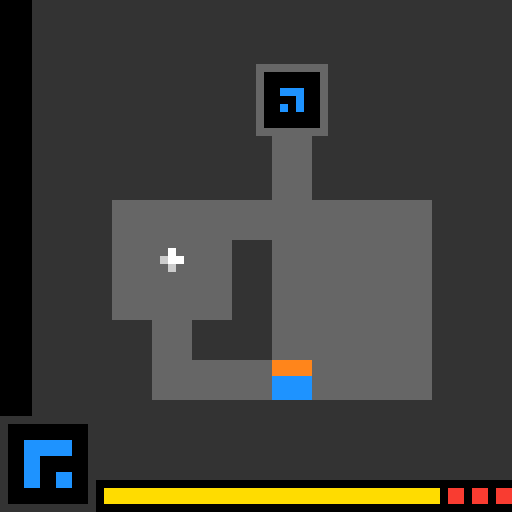

In [7]:
from PIL import Image
from IPython.display import display


def frame_to_image(observation, scale=8):
    """Render the newest frame of an observation as a PIL image."""
    pixels = frame_to_rgb_array(
        steps=0,
        frame=observation.frame[-1],
        scale=scale,
    )
    return Image.fromarray(pixels)


display(frame_to_image(obs))


## 6. Stepping the game

The core loop of any ARC game is:

```text
observation  ->  choose an action  ->  env.step(action)  ->  new observation
```

`env.step(...)` takes an action object, which we get from `env.action_space`. Let's
apply one action and compare the **state** and the **frame** before and after.


In [8]:
actions = {action.name: action for action in env.action_space} # all available actions

before = obs   #Save the before state for comparison
after = env.step(actions["ACTION3"])   # ACTION3 = move left
changed = int((before.frame[-1] != after.frame[-1]).sum())

print("Action objects:", actions)
print()
print("state before:", before.state, "| after:", after.state)
print("levels before:", before.levels_completed, "| after:", after.levels_completed)
print("cells whose color changed:", changed)


Action objects: {'ACTION1': <GameAction.ACTION1: 1>, 'ACTION2': <GameAction.ACTION2: 2>, 'ACTION3': <GameAction.ACTION3: 3>, 'ACTION4': <GameAction.ACTION4: 4>}

state before: GameState.NOT_FINISHED | after: GameState.NOT_FINISHED
levels before: 0 | after: 0
cells whose color changed: 52


Here is the frame **before** and **after** side by side — the difference is what a
single action does to the world.


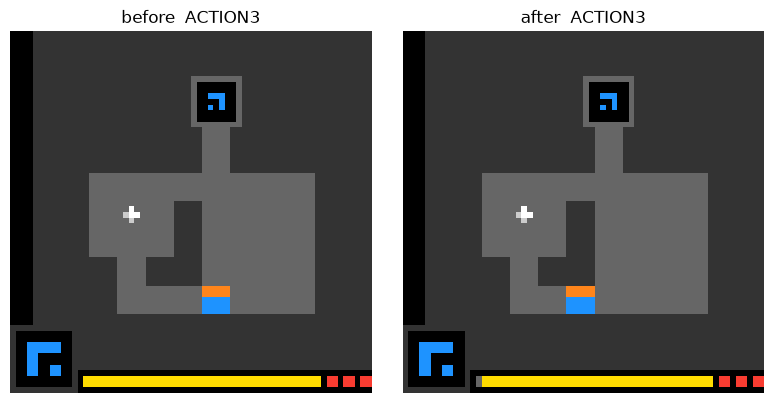

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(frame_to_image(before), interpolation="nearest")
axes[0].set_title("before  ACTION3")
axes[1].imshow(frame_to_image(after), interpolation="nearest")
axes[1].set_title("after  ACTION3")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 7. A tiny wrapper

Playing the game means repeating `reset` and `step` over and over. A small helper
class keeps that tidy and always hands us the newest observation.


In [10]:
class LS20Game:
    """Convenience wrapper around one ARC environment."""

    ACTION_NAMES = {
        "ACTION1": "UP",
        "ACTION2": "DOWN",
        "ACTION3": "LEFT",
        "ACTION4": "RIGHT",
    }

    def __init__(self, arcade, game_id=GAME_ID):
        self.env = arcade.make(game_id)
        self.actions = {a.name: a for a in self.env.action_space}
        self.obs = None

    def reset(self):
        self.obs = self.env.reset()
        return self.obs

    def step(self, action_name):
        self.obs = self.env.step(self.actions[action_name])
        return self.obs

    def render(self, scale=8):
        return frame_to_image(self.obs, scale=scale)

    def done(self):
        return self.obs.state.name in {"WIN", "GAME_OVER"}


game = LS20Game(arcade)
game.reset()

print("Game state:", game.obs.state)
print("Actions:", list(game.actions))


2026-10-14 09:21:49 | INFO | Successfully fetched metadata for game ls20
Game state: GameState.NOT_FINISHED
Actions: ['ACTION1', 'ACTION2', 'ACTION3', 'ACTION4']


## 8. Connecting an LLM

Now we let a language model choose the moves. We talk to an **OpenAI-compatible**
endpoint — the same interface as in the API notebook, only `base_url` and the key
change. The `openai` library works with any such server.


In [11]:
from openai import OpenAI

API_BASE_URL = "https://chat-1.ki-awz.iisys.de/api"
MODEL = "lisa-pro"
API_KEY = Path("api_key.txt").read_text().strip()

client = OpenAI(base_url=API_BASE_URL, api_key=API_KEY)

reply = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "Reply with the single word: ready"}],
)
print(reply.choices[0].message.content)


ready


## 9. Giving the model eyes

The chat API accepts images as **data URIs** (`data:image/png;base64,...`). So we
convert the rendered board into base64 text and attach it to the message.


In [12]:
import base64
import io


def image_to_data_uri(image):
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
    return "data:image/png;base64," + encoded


print("Data URI starts with:", image_to_data_uri(game.render())[:40], "...")


Data URI starts with: data:image/png;base64,iVBORw0KGgoAAAANSU ...


## 10. The game prompt

This is the part worth experimenting with yourself.

Here we hand the model everything explicitly — the goal, the navigation hints, and
the available actions. In a real agent you would **not** spell out the solution: that
is exactly the reasoning we want the model to figure out on its own. Keep the prompt
lean in your own implementation.


In [13]:
GAME_PROMPT = """You are playing the ARC-AGI game ls20.
The orange shape is your player. Move it onto the gray cross on the top left.

Available actions:
ACTION1 = move up
ACTION2 = move down
ACTION3 = move left
ACTION4 = move right

Look at the current board and reply with ONLY one action name.
Example answer: ACTION3"""

print(GAME_PROMPT)


You are playing the ARC-AGI game ls20.
The orange shape is your player. Move it onto the gray cross on the top left.

Available actions:
ACTION1 = move up
ACTION2 = move down
ACTION3 = move left
ACTION4 = move right

Look at the current board and reply with ONLY one action name.
Example answer: ACTION3


We wrap the API call in a small function. It sends the board image plus the prompt
and returns the parsed action. A short regex extracts the first `ACTION1..4` mention,
so stray text does not break the loop.


In [14]:
import re


def ask_llm_for_move(image, history):
    """Return an action name chosen by the LLM, or None if the answer was unusable."""
    message = (
        GAME_PROMPT
        + f"\n\nPrevious actions: {history}"
        + "\nChoose the next action."
    )

    response = client.chat.completions.create(
        model=MODEL,
        messages=[{
            "role": "user",
            "content": [
                {"type": "text", "text": message},
                {"type": "image_url", "image_url": {"url": image_to_data_uri(image)}},
            ],
        }],
    )

    text = response.choices[0].message.content
    match = re.search(r"ACTION[1-4]", text.upper())
    return match.group(0) if match else None


## 11. Let the model play

Now we run the full loop:

```text
render board  ->  ask LLM  ->  parse action  ->  env.step  ->  repeat
```

At every step we clear the previous output and show the current board, so you can
watch the model play. We stop when the game ends or when we hit the step limit.


Step 30/30
Game state: GameState.NOT_FINISHED
Levels completed: 0
Previous actions: ['ACTION3', 'ACTION3', 'ACTION1', 'ACTION3', 'ACTION1', 'ACTION1', 'ACTION1', 'ACTION1', 'ACTION2', 'ACTION1', 'ACTION2', 'ACTION2', 'ACTION1', 'ACTION4', 'ACTION3', 'ACTION1', 'ACTION4', 'ACTION3', 'ACTION2', 'ACTION4', 'ACTION3', 'ACTION2', 'ACTION1', 'ACTION3', 'ACTION4', 'ACTION4', 'ACTION3', 'ACTION4', 'ACTION3']


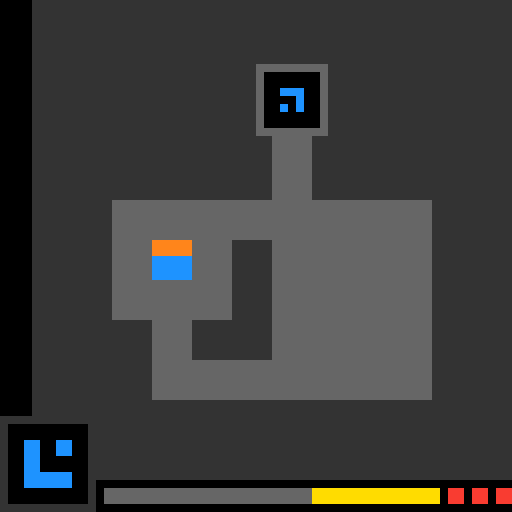

Model chose: ACTION1 (UP)


In [15]:
from IPython.display import clear_output


def play_with_llm(game, max_steps=30):
    obs = game.reset()
    history = []

    for step in range(max_steps):
        image = game.render()

        clear_output(wait=True)
        print(f"Step {step + 1}/{max_steps}")
        print("Game state:", obs.state)
        print("Levels completed:", obs.levels_completed)
        print("Previous actions:", history)
        display(image)

        action = ask_llm_for_move(image, history)
        if action is None:
            print("The model did not return a valid action. Stopping.")
            break

        print("Model chose:", action, f"({LS20Game.ACTION_NAMES[action]})")
        history.append(action)
        obs = game.step(action)

        if game.done():
            clear_output(wait=True)
            print("Finished after", step + 1, "steps.")
            print("Final state:", obs.state)
            print("Previous actions:", history)
            display(game.render())
            break

    return history


actions_taken = play_with_llm(game, max_steps=30)


## 12. What to try next

The loop above is the whole idea behind ARC agents — everything else is about making
the model play *better*. A few interesting to play with, that are sure to help you later on in the year:

1. **Change the prompt.** Describe the goal differently, or stop giving the solution
   away and see whether the model can still find it.
2. **Show more context.** Send the last 2–3 frames instead of only the current one.
3. **Add a memory line.** Keep a running description of what happened and include it
   in the message.
4. **Compare models or scales.** Try a different `MODEL`, or change the render `scale`.
5. **Automatic play.** Drop the LLM call and choose actions from a simple rule to see
   how far a script gets.

The important parts you now know:

* how to **load** a game (`Arcade` + operation modes),
* how the environment represents the world **internally** (`FrameDataRaw`, a numpy
  color-index array),
* how to **step** it (`env.step`) and **render** it (`frame_to_rgb_array`),
* and how to plug in **any LLM** through an OpenAI-compatible API to drive the game.
